IBM tutorial you shared: Quantum Approximate Optimization Algorithm. It demonstrates how to solve the Max-Cut problem using QAOA, first on a five-node graph and then on a 100-node graph using real IBM Quantum hardware

Classical problem → Quantum Hamiltonian → QAOA circuit → Hardware execution → Classical optimization → Measurement → Best solution.



what problem is IBM solving 
IBM uses the MAx -Cut problem
imagine a networking containing five nodes . each nodes must be assigend to one of two group. the mian objectic of this example to maximize the number of edges connecting nodes in diferent groups 


The Quantum Approximate Optimization Algorithm (QAOA) is a hybrid quantum-classical iterative method for solving combinatorial optimization problems. In this tutorial, you will use QAOA to solve the maximum-cut (max-cut) problem — an NP-hard optimization problem with applications in clustering, network science, and statistical physics. Given a graph of nodes connected by edges, the goal is to partition the nodes into two sets such that the number of edges crossing the partition is maximized.


# The Quantum Approximate Optimization Algorithm (QAOA)

The Quantum Approximate Optimization Algorithm (QAOA) is a hybrid quantum-classical iterative method for solving combinatorial optimization problems. In this tutorial, you will use QAOA to solve the maximum-cut (max-cut) problem — an NP-hard optimization problem with applications in clustering, network science, and statistical physics. Given a graph of nodes connected by edges, the goal is to partition the nodes into two sets such that the number of edges crossing the partition is maximized.

**Illustration of a max-cut problem**

## From classical optimization to quantum circuits

Max-cut can be expressed as a classical binary optimization problem. Each node is assigned a binary variable \(x_i \in \{0,1\}\) indicating which set it belongs to. The objective is to maximize the number of edges where the endpoints are in different sets:

\[
\max_{x \in \{0,1\}^n}
\sum_{(i,j)} x_i + x_j - 2x_i x_j.
\]

This is equivalently a Quadratic Unconstrained Binary Optimization (QUBO) problem of the form

\[
\min_x x^T Q x.
\]

Through a standard variable substitution

\[
x_i \rightarrow \frac{1-Z_i}{2},
\]

the QUBO can be rewritten as a cost Hamiltonian whose ground state encodes the optimal solution. In general, this Hamiltonian has both quadratic and linear terms:

\[
H_C =
\sum_{ij} Q_{ij} Z_i Z_j
+
\sum_i b_i Z_i.
\]

For the unweighted max-cut problem considered here, the linear coefficients vanish (\(b_i=0\)) and \(Q_{ij}=1\) for each edge, leaving the simpler form

\[
H_C =
\sum_{(i,j)\in E} Z_i Z_j
\]

that you will build in code below. The more general form above is what you would need to adapt this workflow to weighted graphs or other QUBO-expressible problems.

## How QAOA works

QAOA prepares candidate solutions by applying alternating layers of two operators to an initial superposition state

\[
H^{\otimes n}|0\rangle:
\]

the cost operator

\[
e^{-i\gamma_k H_C}
\]

and a mixer operator

\[
e^{-i\beta_k H_m}.
\]

The angles \(\gamma_k\) and \(\beta_k\) are optimized in a classical feedback loop; the quantum computer evaluates the cost function, and a classical optimizer updates the parameters until convergence. This iterative loop runs within a Quantum Compute session, which keeps the quantum device reserved across iterations for lower latency.

**Circuit diagram with QAOA layers**

For a deeper treatment of QAOA theory, including the full QUBO-to-Hamiltonian derivation, see the QAOA course module.

In this tutorial you will first solve max-cut on a small five-node graph, then scale the same workflow to a 100-node utility-scale problem on real hardware.

**Note on plan access:** This tutorial uses Quantum Compute sessions, which are only available on the Premium Plan. If you are on the Open Plan, you cannot run this tutorial as written; instead, you will need to swap Session for job mode (as in, submit each iteration as an independent job rather than wrapping the optimization loop in `with Session(...)`). The workflow still runs, but each iteration incurs the full queue latency rather than reusing a reserved device. See Overview of available plans for more information.

In [1]:
import matplotlib.pyplot as plt
import rustworkx as rx
from rustworkx.visualization import mpl_draw as draw_graph
import numpy as np
from scipy.optimize import minimize
from collections import defaultdict
from typing import Sequence


from qiskit.quantum_info import SparsePauliOp
from qiskit.circuit.library import QAOAAnsatz
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_ibm_runtime import Session, EstimatorV2 as Estimator
from qiskit_ibm_runtime import SamplerV2 as Sampler

This section walks through each step of the QAOA workflow on a small five-node max-cut instance. Despite the "small-scale" label, this example still runs on real IBM Quantum hardware — the code selects a backend with 127 or more qubits and executes the circuit there.

Initialize your problem by creating a graph with 
n=5
n=5 nodes

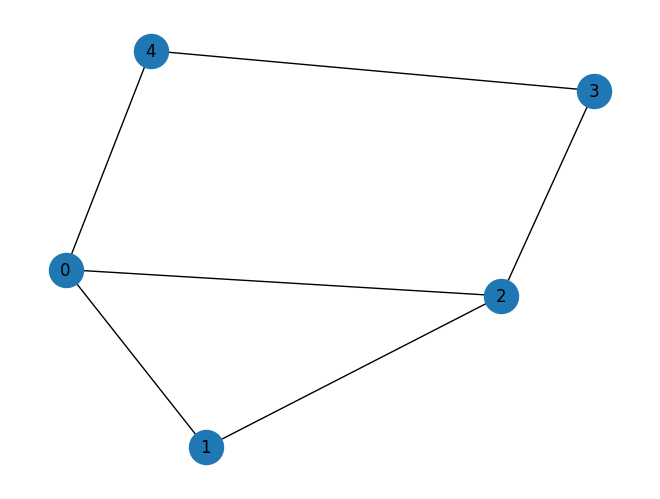

In [2]:
n_small = 5

graph = rx.PyGraph()
graph.add_nodes_from(np.arange(0, n_small, 1))

edge_list = [
    (0, 1, 1.0),
    (0, 2, 1.0),
    (0, 4, 1.0),
    (1, 2, 1.0),
    (2, 3, 1.0),
    (3, 4, 1.0),
]

graph.add_edges_from(edge_list)
draw_graph(graph, node_size=600, with_labels=True)

## Step 1: Map classical inputs to a quantum problem

Map the classical graph into quantum circuits and operators. As described in the Background, for unweighted max-cut the cost Hamiltonian reduces to

\[
H_C = \sum_{(i,j)\in E} Z_i Z_j,
\]

and QAOA uses a parametrized ansatz circuit to prepare candidate ground states of \(H_C\).

### Build the cost Hamiltonian

Convert the graph edges into Pauli \(Z_i Z_j\) terms to construct \(H_C\) (see Background for the derivation).

In [3]:
def build_max_cut_paulis(
    graph: rx.PyGraph,
) -> list[tuple[str, list[int], float]]:
    """Convert graph edges to a list of ZZ Pauli terms.

    The returned list is in the sparse format expected by
    ``SparsePauliOp.from_sparse_list``: each element is
    ``(pauli_string, qubit_indices, coefficient)``.
    """
    pauli_list = []
    for edge in list(graph.edge_list()):
        weight = graph.get_edge_data(edge[0], edge[1])
        pauli_list.append(("ZZ", [edge[0], edge[1]], weight))
    return pauli_list


max_cut_paulis = build_max_cut_paulis(graph)
cost_hamiltonian = SparsePauliOp.from_sparse_list(max_cut_paulis, n_small)
print("Cost Function Hamiltonian:", cost_hamiltonian)

Cost Function Hamiltonian: SparsePauliOp(['IIIZZ', 'IIZIZ', 'ZIIIZ', 'IIZZI', 'IZZII', 'ZZIII'],
              coeffs=[1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j])


#### Build the QAOA ansatz circuit

Use `QAOAAnsatz` to construct the parametrized QAOA circuit from the cost Hamiltonian. Here we use `reps=2` (two QAOA layers, four parameters: `β0, β1, γ0, γ1`).

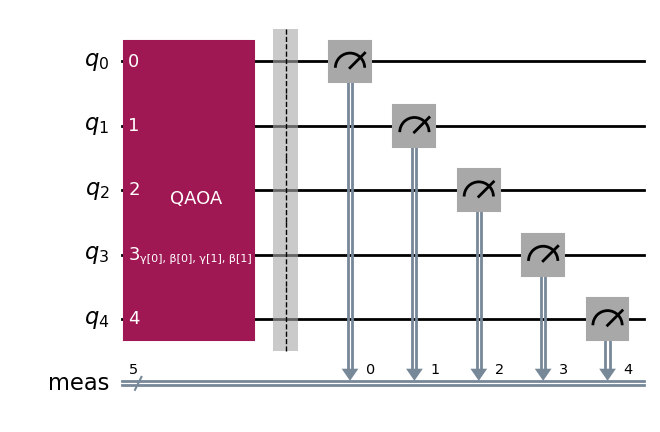

In [4]:
circuit = QAOAAnsatz(cost_operator=cost_hamiltonian, reps=2)
circuit.measure_all()

circuit.draw("mpl")

In [5]:
circuit.parameters

ParameterView([ParameterVectorElement(β[0]), ParameterVectorElement(β[1]), ParameterVectorElement(γ[0]), ParameterVectorElement(γ[1])])

Step 2: Optimize problem for quantum hardware execution
Transpile the abstract circuit into hardware-native instructions. This step handles qubit mapping, gate decomposition, routing, and error suppression. See the transpilation documentation for more information.

In [7]:
from qiskit import QuantumCircuit

from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
from qiskit.transpiler import generate_preset_pass_manager

import numpy as np
import matplotlib.pyplot as plt


def create_bell_stab(initial_layouts):
    """
    Create a circuit for a 1D chain of qubits (number
    of qubits must be a multiple of 4), where a middle
    Bell pair is consumed to create a Bell at the edge.
    Takes as input a list of lists, where each element
    of the list is a 1D chain of physical qubits that is
    used as the initial_layout for the transpiled circuit.
    Returns a list of length-2 tuples, each tuple
    contains a circuit to measure the ZZ stabilizer and
    a circuit to measure the XX stabilizer of the edge
    Bell state.
    """
    bell_circuits = []
    for (
        initial_layout
    ) in initial_layouts:  # Iterate over chains of physical qubits
        assert (
            len(initial_layout) % 4 == 0
        ), "The length of the chain must be a multiple of 4, "
        f"len(inital_layout)={len(initial_layout)}"
        num_pairs = len(initial_layout) // 4

        bell_parallel = QuantumCircuit(4 * num_pairs, 4 * num_pairs)

        for pair_idx in range(num_pairs):
            (q0, q1, q2, q3) = (
                pair_idx * 4,
                pair_idx * 4 + 1,
                pair_idx * 4 + 2,
                pair_idx * 4 + 3,
            )
            (c0, c1) = pair_idx * 4, pair_idx * 4 + 3  # edge qubits
            (ca0, ca1) = pair_idx * 4 + 1, pair_idx * 4 + 2  # middle qubits

            bell_parallel.h(q0)
            bell_parallel.h(q1)
            bell_parallel.cx(q1, q2)
            bell_parallel.cx(q0, q1)
            bell_parallel.cx(q2, q3)
            bell_parallel.h(q2)

        # add barrier BEFORE measurements and add id in conditional
        bell_parallel.barrier()
        for pair_idx in range(num_pairs):
            (q0, q1, q2, q3) = (
                pair_idx * 4,
                pair_idx * 4 + 1,
                pair_idx * 4 + 2,
                pair_idx * 4 + 3,
            )
            (ca0, ca1) = pair_idx * 4 + 1, pair_idx * 4 + 2  # middle qubits

            bell_parallel.measure(q1, ca0)
            bell_parallel.measure(q2, ca1)
        # bell_parallel.barrier() #remove barrier after measurement

        for pair_idx in range(num_pairs):
            (q0, q1, q2, q3) = (
                pair_idx * 4,
                pair_idx * 4 + 1,
                pair_idx * 4 + 2,
                pair_idx * 4 + 3,
            )
            (ca0, ca1) = pair_idx * 4 + 1, pair_idx * 4 + 2  # middle qubits
            with bell_parallel.if_test((ca0, 1)):
                bell_parallel.x(q3)
            with bell_parallel.if_test((ca1, 1)):
                bell_parallel.z(q0)
                bell_parallel.id(q0)  # add id here for correct alignment

        bell_zz = bell_parallel.copy()
        bell_zz.barrier()
        bell_xx = bell_parallel.copy()
        bell_xx.barrier()
        for pair_idx in range(num_pairs):
            (q0, q1, q2, q3) = (
                pair_idx * 4,
                pair_idx * 4 + 1,
                pair_idx * 4 + 2,
                pair_idx * 4 + 3,
            )
            bell_xx.h(q0)
            bell_xx.h(q3)
        bell_xx.barrier()
        for pair_idx in range(num_pairs):
            (q0, q1, q2, q3) = (
                pair_idx * 4,
                pair_idx * 4 + 1,
                pair_idx * 4 + 2,
                pair_idx * 4 + 3,
            )
            (c0, c1) = pair_idx * 4, pair_idx * 4 + 3  # edge qubits

            bell_zz.measure(q0, c0)
            bell_zz.measure(q3, c1)

            bell_xx.measure(q0, c0)
            bell_xx.measure(q3, c1)

        bell_circuits.append(bell_zz)
        bell_circuits.append(bell_xx)

    return bell_circuits


def get_mse(result, initial_layouts):
    """
    given a result object and the initial layouts,
    returns a dict of layouts and their mse
    """
    layout_mse = {}
    for layout_idx, initial_layout in enumerate(initial_layouts):
        layout_mse[tuple(initial_layout)] = {}

        num_pairs = len(initial_layout) // 4

        counts_zz = result[2 * layout_idx].data.c.get_counts()
        total_shots = sum(counts_zz.values())

        # Get ZZ expectation value
        exp_zz_list = []
        for pair_idx in range(num_pairs):
            exp_zz = 0
            for bitstr, shots in counts_zz.items():
                bitstr = bitstr[::-1]  # reverse order to big endian
                b1, b0 = (
                    bitstr[pair_idx * 4],
                    bitstr[pair_idx * 4 + 3],
                )  # parse bitstring to get edge measurements for each 4-q chain
                z_val0 = 1 if b0 == "0" else -1
                z_val1 = 1 if b1 == "0" else -1
                exp_zz += z_val0 * z_val1 * shots
            exp_zz /= total_shots
            exp_zz_list.append(exp_zz)

        counts_xx = result[2 * layout_idx + 1].data.c.get_counts()
        total_shots = sum(counts_xx.values())

        # Get XX expectation value
        exp_xx_list = []
        for pair_idx in range(num_pairs):
            exp_xx = 0
            for bitstr, shots in counts_xx.items():
                bitstr = bitstr[::-1]  # reverse order to big endian
                b1, b0 = (
                    bitstr[pair_idx * 4],
                    bitstr[pair_idx * 4 + 3],
                )  # parse bitstring to get edge measurements for each 4-q chain
                x_val0 = 1 if b0 == "0" else -1
                x_val1 = 1 if b1 == "0" else -1
                exp_xx += x_val0 * x_val1 * shots
            exp_xx /= total_shots
            exp_xx_list.append(exp_xx)

        mse_list = [
            ((exp_zz - 1) ** 2 + (exp_xx - 1) ** 2) / 2
            for exp_zz, exp_xx in zip(exp_zz_list, exp_xx_list)
        ]

        print(f"layout {initial_layout}")
        for idx in range(num_pairs):
            layout_mse[tuple(initial_layout)][
                tuple(initial_layout[4 * idx : 4 * idx + 4])
            ] = mse_list[idx]
            print(
                f"qubits: {initial_layout[4*idx:4*idx+4]}, mse:, "
                f"{round(mse_list[idx],4)}"
            )
            # print(f'exp_zz: {round(exp_zz_list[idx],4)},
            # exp_xx: {round(exp_xx_list[idx],4)}')
        print(" ")
    return layout_mse


def plot_mse_ecdfs(layouts_mse, combine_layouts=False):
    """
    Plot CDF of MSE data for multiple layouts.
    Optionally combine all data in a single CDF
    """

    if not combine_layouts:
        for initial_layout, layouts in layouts_mse.items():
            sorted_layouts = dict(
                sorted(layouts.items(), key=lambda item: item[1])
            )  # sort layouts by mse

            # get layouts and mses
            layout_list = list(sorted_layouts.keys())
            mse_list = np.asarray(list(sorted_layouts.values()))

            # convert to numpy
            x = np.array(mse_list)
            y = np.arange(1, len(x) + 1) / len(x)

            # Prepend (x[0], 0) to start CDF at zero
            x = np.insert(x, 0, x[0])
            y = np.insert(y, 0, 0)

            # Create the plot
            plt.plot(
                x,
                y,
                marker="x",
                linestyle="-",
                label=f"qubits: {initial_layout}",
            )

            # add qubits labels for the edge pairs
            for xi, yi, q in zip(x[1:], y[1:], layout_list):
                plt.annotate(
                    [q[0], q[3]],
                    (xi, yi),
                    textcoords="offset points",
                    xytext=(5, -10),
                    ha="left",
                    fontsize=8,
                )

    elif combine_layouts:
        all_layouts = {}
        all_initial_layout = []
        for (
            initial_layout,
            layouts,
        ) in layouts_mse.items():  # puts together all layout information
            all_layouts.update(layouts)
            all_initial_layout += initial_layout

        sorted_layouts = dict(
            sorted(all_layouts.items(), key=lambda item: item[1])
        )  # sort layouts by mse

        # get layouts and mses
        layout_list = list(sorted_layouts.keys())
        mse_list = np.asarray(list(sorted_layouts.values()))

        # convert to numpy
        x = np.array(mse_list)
        y = np.arange(1, len(x) + 1) / len(x)

        # Prepend (x[0], 0) to start CDF at zero
        x = np.insert(x, 0, x[0])
        y = np.insert(y, 0, 0)

        # Create the plot
        plt.plot(
            x,
            y,
            marker="x",
            linestyle="-",
            label=f"qubits: {sorted(list(set(all_initial_layout)))}",
        )

        # add qubit labels for the edge pairs
        for xi, yi, q in zip(x[1:], y[1:], layout_list):
            plt.annotate(
                [q[0], q[3]],
                (xi, yi),
                textcoords="offset points",
                xytext=(5, -10),
                ha="left",
                fontsize=8,
            )

    plt.xscale("log")
    plt.xlabel("Mean squared error of ⟨ZZ⟩ and ⟨XX⟩")
    plt.ylabel("Cumulative distribution function")
    plt.title("CDF for different initial layouts")
    plt.grid(alpha=0.3)
    plt.show()

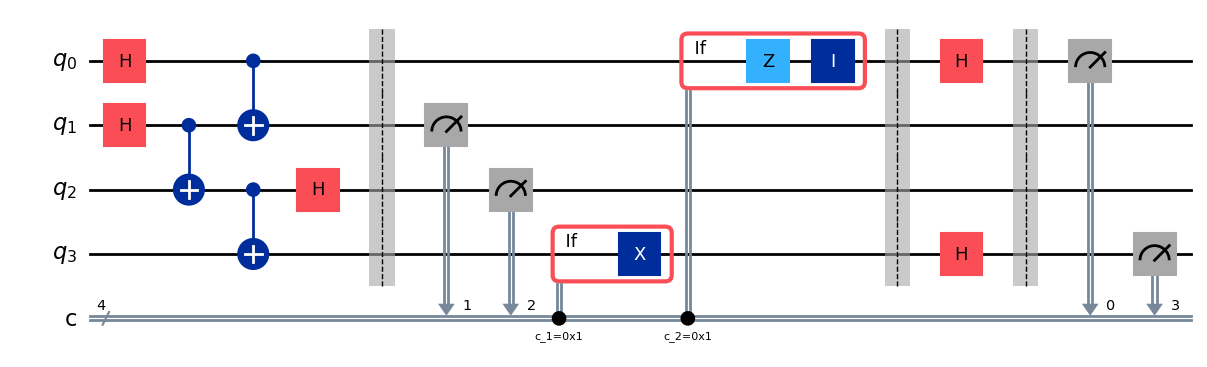

In [8]:
from qiskit_aer import AerSimulator

# 4-qubit chain for simulation
sim_layout = [[0, 1, 2, 3]]

aer_backend = AerSimulator()
sim_circuits = create_bell_stab(sim_layout)
sim_circuits[1].draw("mpl", fold=-1, idle_wires=False)

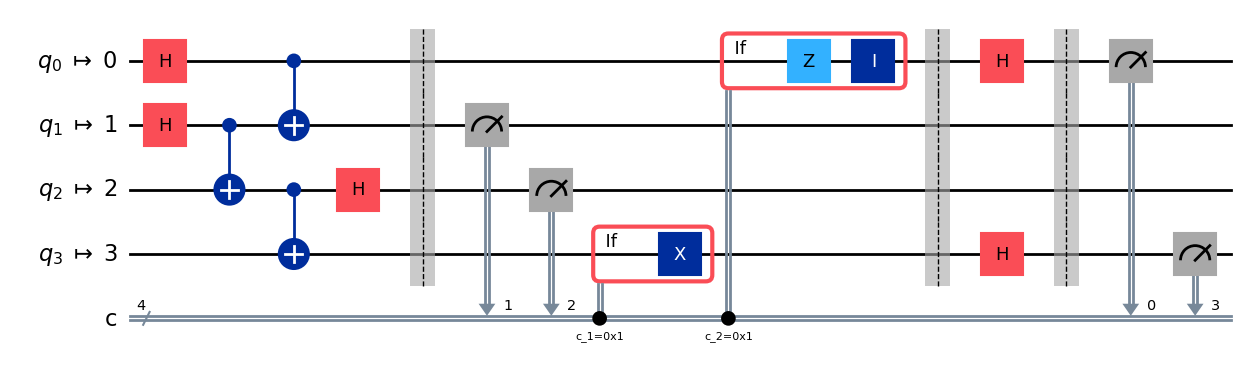

In [9]:
pm_sim = generate_preset_pass_manager(
    optimization_level=0, backend=aer_backend, initial_layout=sim_layout[0]
)
isa_sim_circuits = pm_sim.run(sim_circuits)
isa_sim_circuits[1].draw("mpl", fold=-1, idle_wires=False)
